In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:

df = pd.read_csv("Admission_Prediction_TimeSeries_Ready.csv")

print("Dataset shape (rows, columns):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

Dataset shape (rows, columns): (1000, 12)

Column names:
['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit', 'Application_DateTime', 'University_Name', 'region']

First five rows:


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.92,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.76,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.72,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.80,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.65,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [3]:
# Check data types, missing values, and duplicate rows before analysis.
print("Dataset information:")
df.info()

print("\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nSummary of numerical columns:")
display(df.describe().T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Serial No.            1000 non-null   int64  
 1   GRE Score             1000 non-null   int64  
 2   TOEFL Score           1000 non-null   int64  
 3   University Rating     1000 non-null   int64  
 4   SOP                   1000 non-null   float64
 5   LOR                   1000 non-null   float64
 6   CGPA                  1000 non-null   float64
 7   Research              1000 non-null   int64  
 8   Chance of Admit       1000 non-null   float64
 9   Application_DateTime  1000 non-null   object 
 10  University_Name       1000 non-null   object 
 11  region                1000 non-null   object 
dtypes: float64(4), int64(5), object(3)
memory usage: 93.9+ KB

Missing values per column:


,Missing Values
Serial No.,0
GRE Score,0
TOEFL Score,0
University Rating,0
SOP,0
LOR,0
CGPA,0
Research,0
Chance of Admit,0
Application_DateTime,0



Number of duplicate rows: 0

Summary of numerical columns:


,count,mean,std,min,25%,50%,75%,max
Serial No.,1000.0,500.50000,288.819436,1.00,250.7500,500.50,750.25,1000.00
GRE Score,1000.0,315.96500,13.415653,290.00,305.0000,316.00,326.25,340.00
TOEFL Score,1000.0,106.56400,7.634277,92.00,101.0000,107.00,113.00,120.00
University Rating,1000.0,3.01500,1.317768,1.00,2.0000,3.00,4.00,5.00
SOP,1000.0,3.39350,1.027279,0.90,2.5000,3.50,4.00,5.10
LOR,1000.0,3.40670,0.891864,0.90,3.0000,3.50,4.00,5.10
CGPA,1000.0,8.58979,0.612170,6.77,8.1800,8.58,9.07,9.95
Research,1000.0,0.50300,0.500241,0.00,0.0000,1.00,1.00,1.00
Chance of Admit,1000.0,0.71777,0.145910,0.32,0.6375,0.72,0.82,0.97


In [4]:
# Select numeric columns only; text and date columns are not used
# in Pearson correlation calculations.
numeric_df = df.select_dtypes(include="number").copy()

# Serial No. is an identifier, not an applicant characteristic.
numeric_df = numeric_df.drop(columns=["Serial No."], errors="ignore")

# Replace positive/negative infinity with missing values, if any.
numeric_df = numeric_df.replace([np.inf, -np.inf], np.nan)


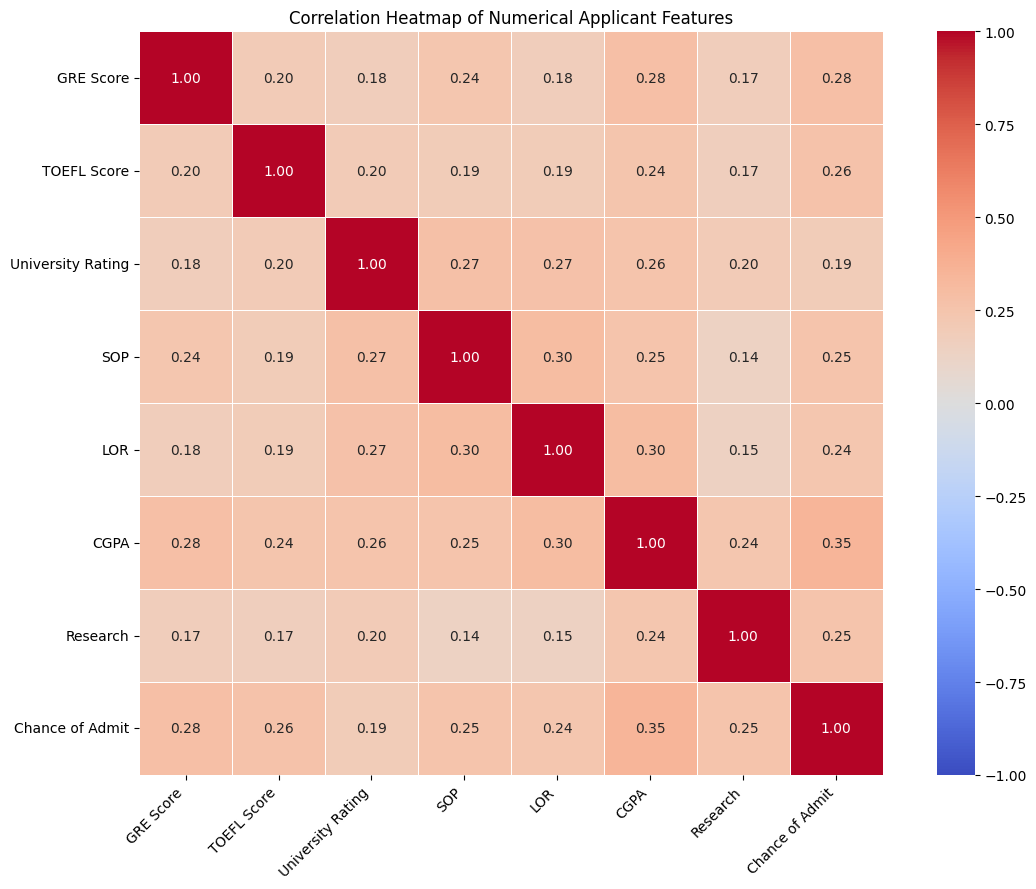

In [5]:
# Correlation uses available pairs of values in each column pair.
# Values range from -1 (negative relationship) to +1 (positive relationship).
corr = numeric_df.corr(method="pearson")

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr,
    annot=True,         
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    square=True
)
plt.title("Correlation Heatmap of Numerical Applicant Features")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

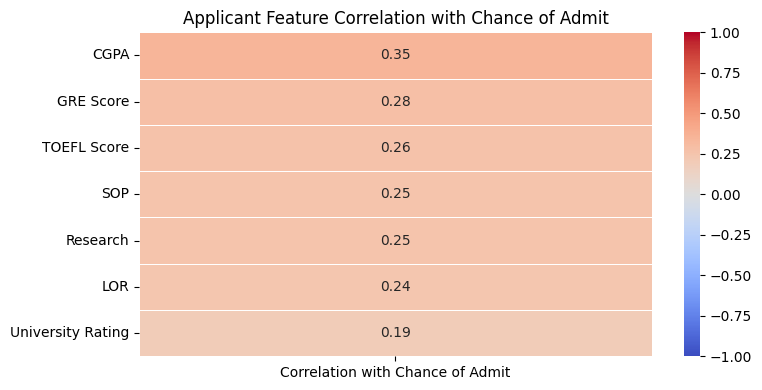

,Correlation with Chance of Admit
CGPA,0.347903
GRE Score,0.282559
TOEFL Score,0.264312
SOP,0.253922
Research,0.251129
LOR,0.239704
University Rating,0.193840


In [6]:
# Rank each numerical feature by its correlation with the target.
target = "Chance of Admit"

if target in corr.columns:
    target_corr = corr[target].drop(labels=[target], errors="ignore")
    target_corr = target_corr.sort_values(ascending=False)

    plt.figure(figsize=(8, max(4, 0.45 * len(target_corr))))
    sns.heatmap(
        target_corr.to_frame("Correlation with Chance of Admit"),
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        linewidths=0.5
    )
    plt.title("Applicant Feature Correlation with Chance of Admit")
    plt.tight_layout()
    plt.show()

    display(target_corr.to_frame("Correlation with Chance of Admit"))
else:
    print(f"Target column '{target}' was not found.")

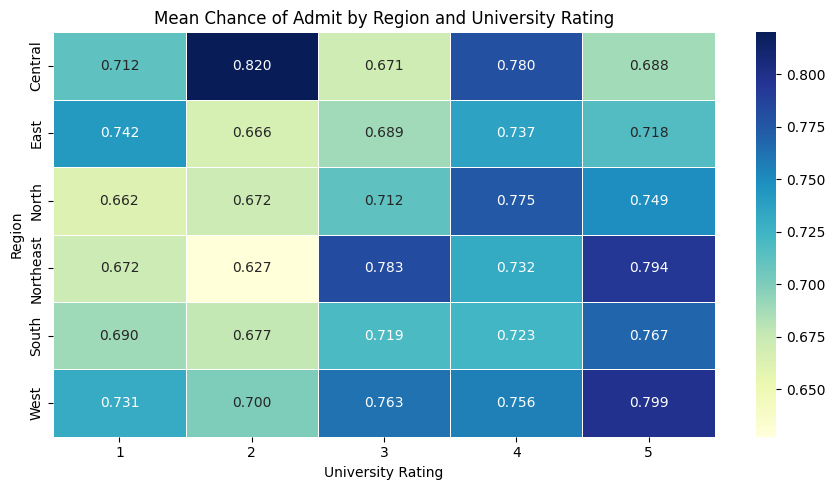

Applicant counts in each region-rating group:


University Rating,1,2,3,4,5
region,,,,,
Central,9,1,8,3,5
East,9,32,30,24,20
North,46,72,69,59,59
Northeast,4,4,7,5,5
South,54,90,103,69,63
West,27,36,29,32,26


In [7]:
# Each cell shows the mean admission chance for a region and university rating.
required = ["region", "University Rating", "Chance of Admit"]

if all(col in df.columns for col in required):
    region_rating = df.pivot_table(
        index="region",
        columns="University Rating",
        values="Chance of Admit",
        aggfunc="mean"
    )

    plt.figure(figsize=(9, 5))
    sns.heatmap(
        region_rating,
        annot=True,
        fmt=".3f",
        cmap="YlGnBu",
        linewidths=0.5,
        mask=region_rating.isna()
    )
    plt.title("Mean Chance of Admit by Region and University Rating")
    plt.xlabel("University Rating")
    plt.ylabel("Region")
    plt.tight_layout()
    plt.show()

    print("Applicant counts in each region-rating group:")
    display(df.pivot_table(
        index="region",
        columns="University Rating",
        values="Chance of Admit",
        aggfunc="count"
    ))
else:
    print("Required columns are missing:", [c for c in required if c not in df.columns])

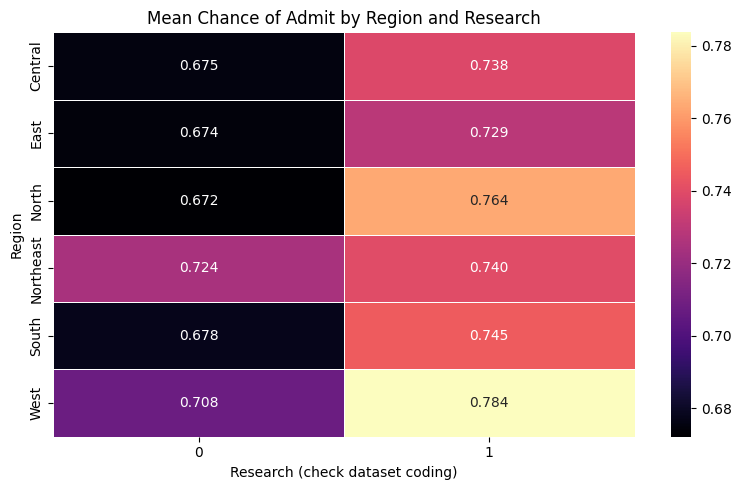

In [8]:
# This heatmap compares average admission chance across region and research experience.
# Research is commonly coded as 0 = no and 1 = yes; verify this meaning in your data.
required = ["region", "Research", "Chance of Admit"]

if all(col in df.columns for col in required):
    region_research = df.pivot_table(
        index="region",
        columns="Research",
        values="Chance of Admit",
        aggfunc="mean"
    )

    plt.figure(figsize=(8, 5))
    sns.heatmap(
        region_research,
        annot=True,
        fmt=".3f",
        cmap="magma",
        linewidths=0.5,
        mask=region_research.isna()
    )
    plt.title("Mean Chance of Admit by Region and Research")
    plt.xlabel("Research (check dataset coding)")
    plt.ylabel("Region")
    plt.tight_layout()
    plt.show()
else:
    print("Required columns are missing:", [c for c in required if c not in df.columns])

In [9]:
# Calculate the average applicant scores and admission chance for each university.
# This helps compare several numerical dimensions across universities.
group_columns = [
    "GRE Score", "TOEFL Score", "CGPA", "SOP", "LOR",
    "University Rating", "Chance of Admit"
]
available = [c for c in group_columns if c in df.columns]

if "University_Name" in df.columns and available:
    university_means = df.groupby("University_Name")[available].mean()

    university_counts = df.groupby("University_Name").size().sort_values(ascending=False)
    university_means = university_means.loc[university_counts.index]

    print("Number of records per university:")
    display(university_counts.to_frame("Applicant Count"))
else:
    print("University_Name or numerical score columns are missing.")

Number of records per university:


,Applicant Count
University_Name,
National Institute of Technology Warangal,32
Jamia Millia Islamia,31
Indian Institute of Technology Kharagpur,31
University of Madras,30
Indian Institute of Technology Roorkee,28
Kalinga Institute of Industrial Technology,26
Indian Institute of Technology Indore,26
Amrita Vishwa Vidyapeetham,26
Visvesvaraya Technological University,26


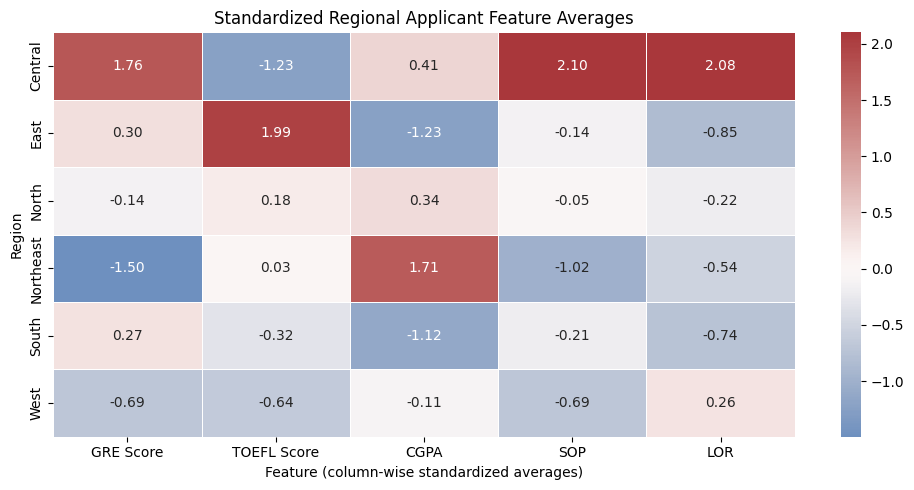

In [10]:
# Compare the average values of several applicant features across regions.
score_columns = ["GRE Score", "TOEFL Score", "CGPA", "SOP", "LOR"]
available_scores = [c for c in score_columns if c in df.columns]

if "region" in df.columns and available_scores:
    regional_means = df.groupby("region")[available_scores].mean()

    # Z-score each feature column so differently scaled measures
    # can be compared by relative position within that feature.
    regional_z = (regional_means - regional_means.mean()) / regional_means.std(ddof=0)
    regional_z = regional_z.replace([np.inf, -np.inf], np.nan)

    plt.figure(figsize=(10, 5))
    sns.heatmap(
        regional_z,
        annot=True,
        fmt=".2f",
        cmap="vlag",
        center=0,
        linewidths=0.5
    )
    plt.title("Standardized Regional Applicant Feature Averages")
    plt.xlabel("Feature (column-wise standardized averages)")
    plt.ylabel("Region")
    plt.tight_layout()
    plt.show()
else:
    print("Region or applicant score columns are missing.")

In [11]:
# Use absolute correlation so strong positive and negative pairs are both found.
# Only the upper triangle is inspected so each pair appears once.
abs_corr = corr.abs()
upper = abs_corr.where(np.triu(np.ones(abs_corr.shape), k=1).astype(bool))

threshold = 0.80
pairs = upper.stack().reset_index()
pairs.columns = ["Feature 1", "Feature 2", "Absolute Correlation"]
pairs = pairs[pairs["Absolute Correlation"] >= threshold]
pairs = pairs.sort_values("Absolute Correlation", ascending=False)

print(f"Feature pairs with absolute correlation >= {threshold}:")
if pairs.empty:
    print("No pairs meet the threshold.")
else:
    display(pairs)

Feature pairs with absolute correlation >= 0.8:
No pairs meet the threshold.


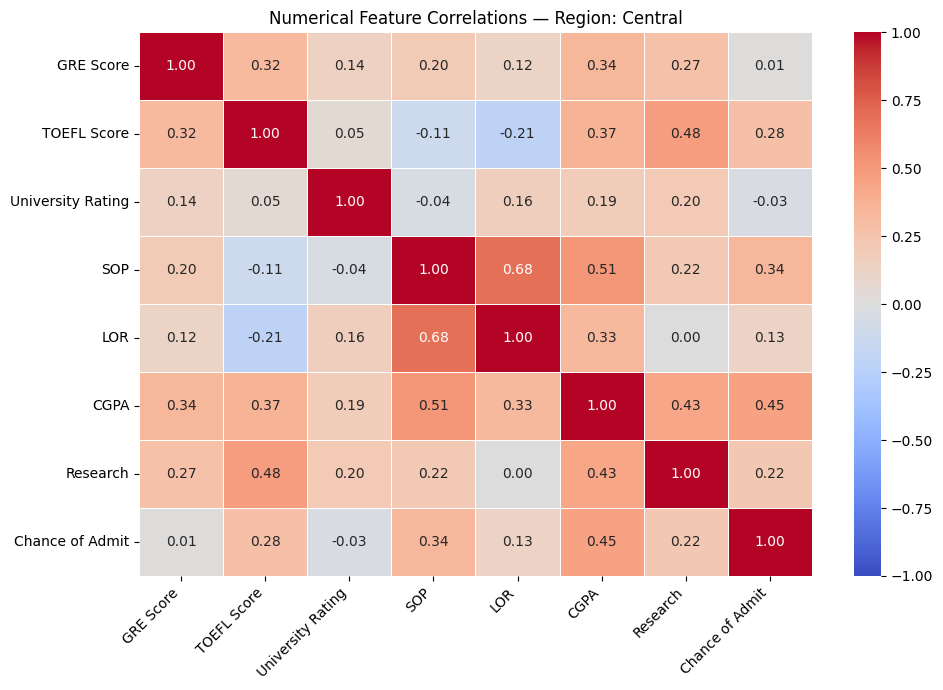

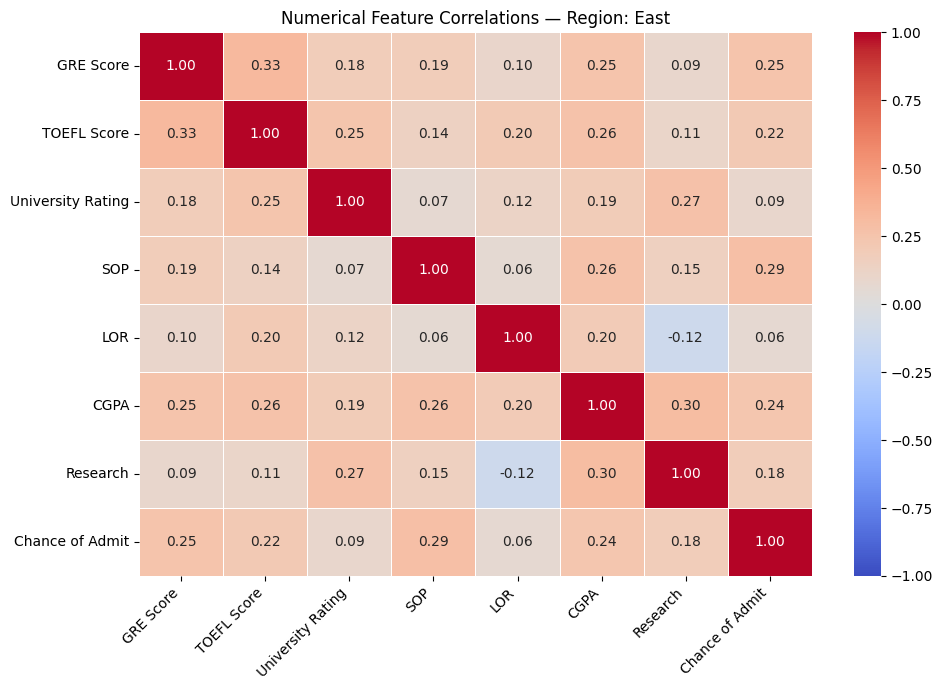

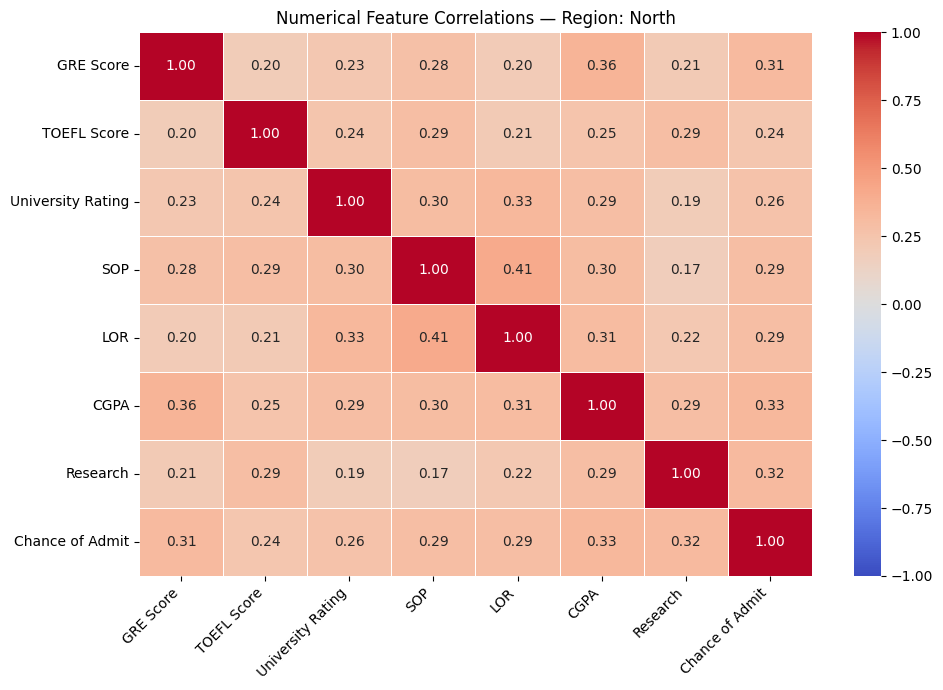

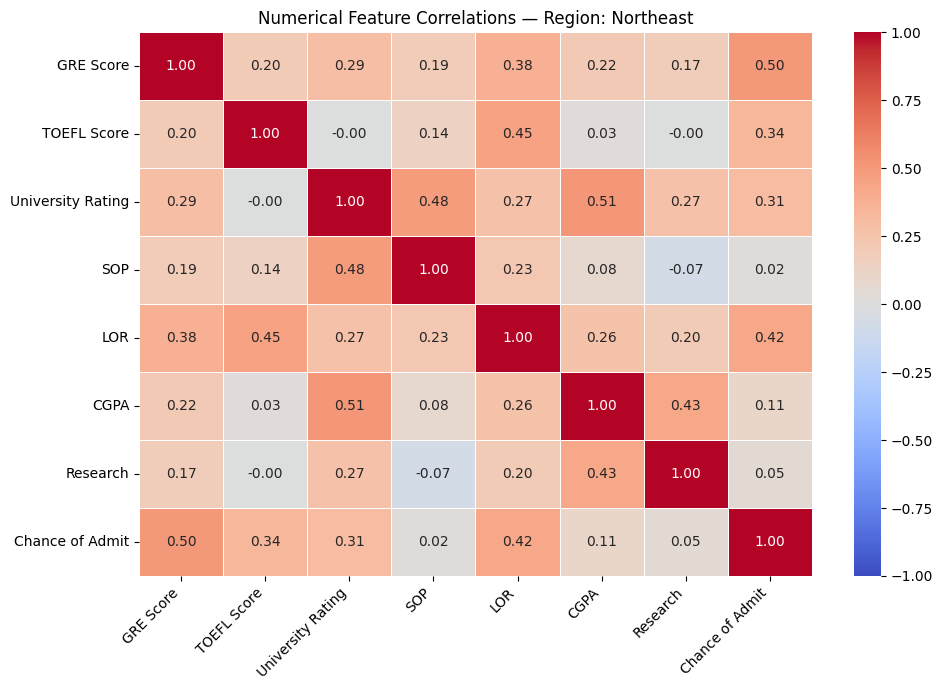

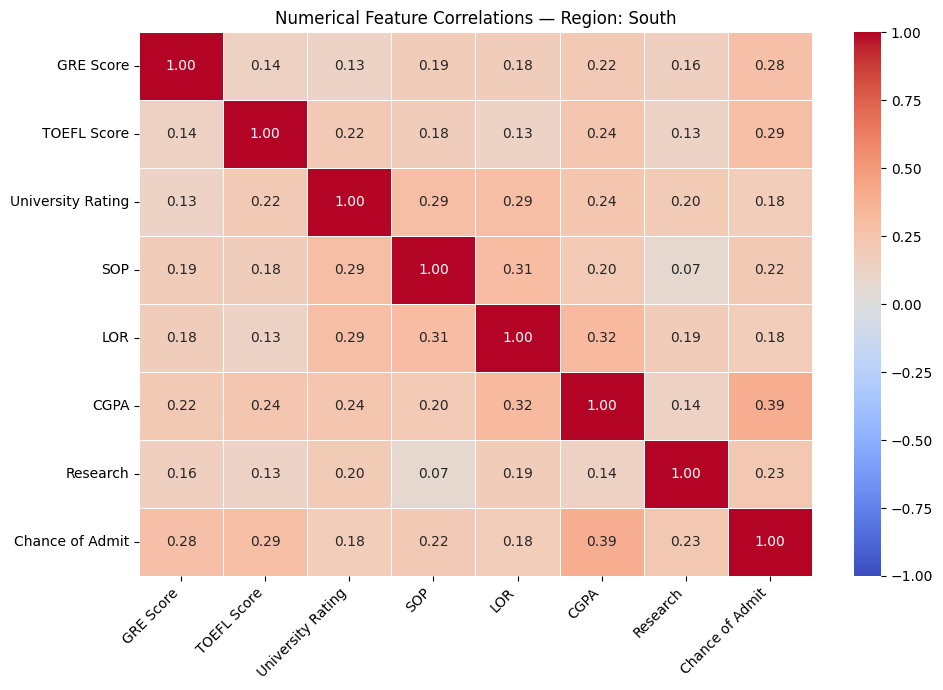

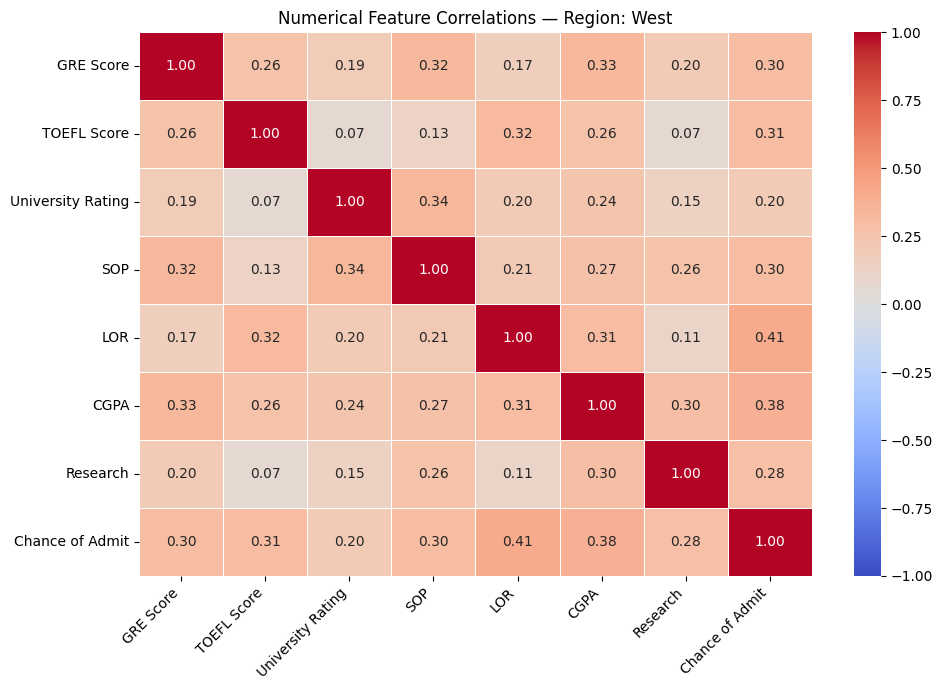

In [12]:
# Correlations may differ between groups. This cell produces one correlation
# heatmap per region, using only numeric applicant features.
# Groups with too few complete observations are skipped for reliability.
if "region" in df.columns:
    for region_name, group in df.groupby("region"):
        group_numeric = group.select_dtypes(include="number").drop(
            columns=["Serial No."], errors="ignore"
        )
        group_corr = group_numeric.corr()

        if len(group) < 5 or group_corr.empty:
            print(f"Skipping {region_name}: too few rows or no numeric features.")
            continue

        plt.figure(figsize=(10, 7))
        sns.heatmap(
            group_corr,
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            vmin=-1,
            vmax=1,
            center=0,
            linewidths=0.4
        )
        plt.title(f"Numerical Feature Correlations — Region: {region_name}")
        plt.xticks(rotation=45, ha="right")
        plt.yticks(rotation=0)
        plt.tight_layout()
        plt.show()
else:
    print("The region column was not found.")